# Part A – Optical Sensor Heart Rate

## A.1 Load the data
The CSV has no header and two columns: time (s) and reflected light intensity.
The sampling rate is computed from the mean time step between samples.

In [2]:
import numpy as np                      # numerical arrays and maths
import pandas as pd                     # reading the CSV file
import matplotlib.pyplot as plt         # plotting
from scipy.signal import butter, filtfilt, detrend, find_peaks  # signal processing tools


def load_signal(path):
    """Load the optical sensor CSV and return time, signal and sampling rate."""
    df = pd.read_csv(path, header=None, names=["time", "amplitude"])  # file has no header row
    t = df["time"].to_numpy()           # time stamps in seconds
    x = df["amplitude"].to_numpy()      # reflected light intensity
    fs = 1 / np.mean(np.diff(t))        # sampling rate = 1 / mean time step
    return t, x, fs


t, x, fs = load_signal("data/heart_beat_signal.csv")                  # load the data
print(f"{len(t)} samples, fs = {fs:.2f} Hz, duration = {t[-1]:.1f} s")  # quick sanity check

913 samples, fs = 29.97 Hz, duration = 30.5 s


## A.2 Plot the raw signal (Task 1.1)
The raw reflected-light intensity is plotted against time to inspect the signal quality before processing.

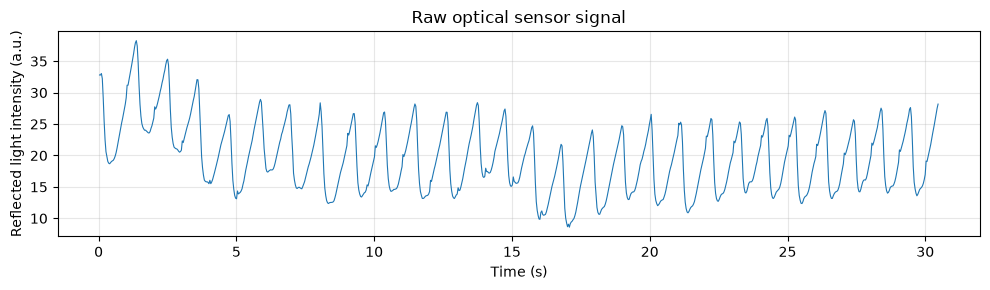

In [3]:
fig, ax = plt.subplots(figsize=(10, 3))                  # wide figure suits a time series
ax.plot(t, x, linewidth=0.8)                             # raw signal against time
ax.set_xlabel("Time (s)")                                # x-axis label with units
ax.set_ylabel("Reflected light intensity (a.u.)")        # a.u. = arbitrary units
ax.set_title("Raw optical sensor signal")                # figure title
ax.grid(alpha=0.3)                                       # light grid makes values easier to read
fig.tight_layout()                                       # stop labels being cut off
fig.savefig("figures/A1_raw_signal.png", dpi=200)        # save a high-resolution copy for the report
plt.show()                                               # display the figure in the notebook